In [72]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from xgboost import plot_importance


import xgboost as xgb
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import PassiveAggressiveRegressor
from sklearn.linear_model import BayesianRidge
from sklearn.linear_model import HuberRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import LassoCV
from sklearn.linear_model import OrthogonalMatchingPursuit
from sklearn.linear_model import TweedieRegressor
from catboost import CatBoostRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor



# Read Data

In [2]:
trainingData = pd.read_csv('train.csv')

testingData = pd.read_csv('test.csv')

In [3]:
trainingData

,id,id_seqpos,sequence,structure,predicted_loop_type,reactivity,reactivity_error,deg_Mg_pH10,deg_error_Mg_pH10,deg_pH10,...,b4_structure,a4_structure,b4_predicted_loop_type,a4_predicted_loop_type,b5_sequence,a5_sequence,b5_structure,a5_structure,b5_predicted_loop_type,a5_predicted_loop_type
0,id_159f0ff46,id_159f0ff46_44,A,.,H,1.7786,0.1195,0.7346,0.0790,0.3680,...,(,),S,S,C,A,.,),I,S
1,id_d73546f4e,id_d73546f4e_38,G,.,I,0.4397,0.1033,0.1630,0.0799,0.0878,...,(,.,S,H,C,C,.,.,B,H
2,id_f3037fedf,id_f3037fedf_34,G,(,S,0.1120,0.1375,0.0000,0.0744,0.1835,...,(,(,S,S,A,G,(,(,S,S
3,id_468300749,id_468300749_12,G,(,S,0.0622,0.0471,0.1179,0.1075,0.0657,...,.,(,E,S,A,U,.,(,E,S
4,id_69e3878a2,id_69e3878a2_28,U,(,S,0.1378,0.1352,0.4069,0.2168,0.3375,...,(,(,S,S,G,G,(,.,S,H
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
130555,id_796128149,id_796128149_27,U,),S,0.1244,0.0393,0.2672,0.0728,0.1479,...,),),S,S,A,A,.,.,H,M
130556,id_8a466e770,id_8a466e770_39,A,.,X,0.0201,0.0351,0.1271,0.0583,0.0580,...,.,.,H,X,A,U,.,.,H,X
130557,id_998669e76,id_998669e76_52,A,.,H,0.4597,0.0601,0.2014,0.0515,0.2838,...,.,.,H,I,U,U,.,),H,S
130558,id_6fe4a1abc,id_6fe4a1abc_45,G,.,I,0.3634,0.1063,0.1928,0.0738,0.1885,...,),.,S,I,G,G,),),S,S


In [4]:
def impute_outliers_xgb(data, target_col, feature_cols):
    df = data.copy()
    
    valid_mask = (df[target_col] >= 0) & (df[target_col] <= 1)
    invalid_mask = ~valid_mask
    
    X_train = df.loc[valid_mask, feature_cols]
    y_train = df.loc[valid_mask, target_col]
    
    X_predict = df.loc[invalid_mask, feature_cols]
    
    if not X_predict.empty:
        xgb_regressor = xgb.XGBRegressor(random_state=42)
        xgb_regressor.fit(X_train, y_train)
        
        predicted_values = xgb_regressor.predict(X_predict)
        df.loc[invalid_mask, target_col] = predicted_values
        
    return df

# Handling Outliers & Imputation (Cross-Imputation)


In [5]:
degradation_cols = [
    'reactivity', 'reactivity_error', 
    'deg_Mg_pH10', 'deg_error_Mg_pH10', 
    'deg_pH10', 'deg_error_pH10', 
    'deg_Mg_50C', 'deg_error_Mg_50C', 
    'deg_50C', 'deg_error_50C'
]

for target in degradation_cols:
    features = [col for col in degradation_cols if col != target]
    
    trainingData = impute_outliers_xgb(trainingData, target_col=target, feature_cols=features)

# Handling Outliers in Test Data


In [6]:
test_impute_cols = [
    'reactivity_error', 'deg_error_Mg_pH10', 'deg_pH10', 
    'deg_error_pH10', 'deg_error_Mg_50C', 'deg_50C', 'deg_error_50C'
]

for target in test_impute_cols:
    features = [col for col in test_impute_cols if col != target]
    
    testingData = impute_outliers_xgb(testingData, target_col=target, feature_cols=features)

# Encoding Categorical Features (RNA Tokens)

In [7]:
def encode_rna_features(data):
    df = data.copy()
    
    encoding_map = {
        # Sequence (A, G, U, C)
        'A': 0, 'G': 1, 'U': 2, 'C': 3,
        
        # Structure (Paired/Unpaired)
        '.': 0, '(': 1, ')': 2,
        
        # Predicted Loop Type
        'B': 0, 'E': 1, 'H': 2, 'I': 3, 'M': 4, 'S': 5, 'X': 6,
        
        # Unknown or Missing values
        '-1': -1 
    }
    
    object_cols = df.select_dtypes(include=['object']).columns
    
    df[object_cols] = df[object_cols].replace(encoding_map)
    
    return df

#  Applying the Encoding to Datasets


In [8]:
train_encoded = encode_rna_features(trainingData)
test_encoded = encode_rna_features(testingData)

C:\Users\MaenQawasmeh\AppData\Local\Temp\ipykernel_25296\3649073297.py:20: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[object_cols] = df[object_cols].replace(encoding_map)
C:\Users\MaenQawasmeh\AppData\Local\Temp\ipykernel_25296\3649073297.py:20: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[object_cols] = df[object_cols].replace(encoding_map)


# Dropping Identifier Columns

In [9]:
test_submission_ids = test_encoded['id_seqpos'].copy()

train_encoded = train_encoded.drop(['id', 'id_seqpos'], axis=1)

test_encoded = test_encoded.drop(['id', 'id_seqpos'], axis=1)

# Splitting Features (X) and Targets (y)

In [10]:
scored_targets = ['reactivity', 'deg_Mg_pH10', 'deg_Mg_50C']

leakage_cols = [
    'deg_pH10', 'deg_50C',
    'reactivity_error', 'deg_error_Mg_pH10', 'deg_error_pH10',
    'deg_error_Mg_50C', 'deg_error_50C'
]

X = train_encoded.drop(columns = scored_targets + leakage_cols)

y = train_encoded[scored_targets]

In [13]:
X_train, X_val, y_train, y_val = train_test_split(X, y,test_size=0.33,random_state=42 )

# Model Training 

Gradient Boosting

In [15]:
base_model = GradientBoostingRegressor(random_state=42)

multi_target_regressor = MultiOutputRegressor(base_model)

multi_target_regressor.fit(X_train, y_train)

predictions = multi_target_regressor.predict(X_val)

Lasso Regression

In [19]:
lasso_base = Lasso(random_state=42)

lasso_multi_target = MultiOutputRegressor(lasso_base)

lasso_multi_target.fit(X_train, y_train)

predictions_lasso = lasso_multi_target.predict(X_val)

Ridge Regression

In [ ]:
ridge_base = Ridge(random_state=42)

ridge_multi_target = MultiOutputRegressor(ridge_base)

ridge_multi_target.fit(X_train, y_train)

predictions_ridge = ridge_multi_target.predict(X_val)

K-Nearest Neighbors

In [23]:
knn_base = KNeighborsRegressor()

knn_multi_target = MultiOutputRegressor(knn_base)

knn_multi_target.fit(X_train, y_train)

predictions_knn = knn_multi_target.predict(X_val)

ElasticNet Regression

In [26]:
elastic_net_base = ElasticNet(random_state=42)

elastic_net_multi_target = MultiOutputRegressor(elastic_net_base)

elastic_net_multi_target.fit(X_train, y_train)

predictions_elastic_net = elastic_net_multi_target.predict(X_val)

Decision Tree Regressor

In [27]:
from sklearn.multioutput import MultiOutputRegressor

dt_base = DecisionTreeRegressor(random_state=42)

dt_multi_target = MultiOutputRegressor(dt_base)

dt_multi_target.fit(X_train, y_train)

predictions_dt = dt_multi_target.predict(X_val)

Passive Aggressive Regressor

In [29]:
pa_base = PassiveAggressiveRegressor(random_state=42)

pa_multi_target = MultiOutputRegressor(pa_base)

pa_multi_target.fit(X_train, y_train)

predictions_pa = pa_multi_target.predict(X_val)

Bayesian Ridge Regression

In [31]:
bayesian_base = BayesianRidge()

bayesian_multi_target = MultiOutputRegressor(bayesian_base)

bayesian_multi_target.fit(X_train, y_train)

predictions_bayesian = bayesian_multi_target.predict(X_val)

Huber Regressor

In [33]:
huber_base = HuberRegressor()

huber_multi_target = MultiOutputRegressor(huber_base)

huber_multi_target.fit(X_train, y_train)

predictions_huber = huber_multi_target.predict(X_val)

AdaBoost Regressor

In [35]:
adaboost_base = AdaBoostRegressor(random_state=42)

adaboost_multi_target = MultiOutputRegressor(adaboost_base)

adaboost_multi_target.fit(X_train, y_train)

predictions_adaboost = adaboost_multi_target.predict(X_val)

RidgeCV Regressor

In [37]:
ridgecv_base = RidgeCV()

ridgecv_multi_target = MultiOutputRegressor(ridgecv_base)

ridgecv_multi_target.fit(X_train, y_train)

predictions_ridgecv = ridgecv_multi_target.predict(X_val)

LassoCV Regressor

In [39]:
lassocv_base = LassoCV(random_state=42)

lassocv_multi_target = MultiOutputRegressor(lassocv_base)

lassocv_multi_target.fit(X_train, y_train)

predictions_lassocv = lassocv_multi_target.predict(X_val)

Orthogonal Matching Pursuit

In [41]:
omp_base = OrthogonalMatchingPursuit()

omp_multi_target = MultiOutputRegressor(omp_base)

omp_multi_target.fit(X_train, y_train)

predictions_omp = omp_multi_target.predict(X_val)

Tweedie Regressor

In [43]:
tweedie_base = TweedieRegressor()

tweedie_multi_target = MultiOutputRegressor(tweedie_base)

tweedie_multi_target.fit(X_train, y_train)

predictions_tweedie = tweedie_multi_target.predict(X_val)

c:\Users\MaenQawasmeh\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\MaenQawasmeh\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\MaenQawasmeh\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\MaenQawasmeh\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\MaenQawasmeh\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    h

CatBoost Regressor

In [45]:
catboost_base = CatBoostRegressor(verbose=False, random_state=42)

catboost_multi_target = MultiOutputRegressor(catboost_base)

catboost_multi_target.fit(X_train, y_train)

predictions_catboost = catboost_multi_target.predict(X_val)

HistGradientBoosting Regressor

In [ ]:
hist_gb_base = HistGradientBoostingRegressor(random_state=42)

hist_gb_multi_target = MultiOutputRegressor(hist_gb_base)

hist_gb_multi_target.fit(X_train, y_train)

predictions_hist_gb = hist_gb_multi_target.predict(X_val)

LightGBM Regressor

In [49]:
lgbm_base = LGBMRegressor(random_state=42)

lgbm_multi_target = MultiOutputRegressor(lgbm_base)

lgbm_multi_target.fit(X_train, y_train)

predictions_lgbm = lgbm_multi_target.predict(X_val)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001821 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 169
[LightGBM] [Info] Number of data points in the train set: 87475, number of used features: 33
[LightGBM] [Info] Start training from score 0.315438
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001621 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 169
[LightGBM] [Info] Number of data points in the train set: 87475, number of used features: 33
[LightGBM] [Info] Start training from score 0.359815
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001395 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough,

XGBoost Regressor

In [51]:
xgb_model = XGBRegressor(random_state=42)

xgb_model.fit(X_train, y_train)

predictions_xgb = xgb_model.predict(X_val)

Random Forest Regressor

In [ ]:
rf_base = RandomForestRegressor(random_state=42)

rf_multi_target = MultiOutputRegressor(rf_base)

rf_multi_target.fit(X_train, y_train)

predictions_rf = rf_multi_target.predict(X_val)

# Hyperparameter Tuning (XGBoost)


In [73]:

xgb_model_tuned = XGBRegressor(
    max_depth=6,
    learning_rate=0.1,
    colsample_bytree=0.9,
    reg_alpha=5,
    reg_lambda=6,
    min_child_weight=2,
    n_estimators=1500, 
    random_state=42
)

xgb_model_tuned.fit(X_train, y_train)

predictions_xgb_tuned = xgb_model_tuned.predict(X_val)

In [74]:
def mcrmse_loss(y_true, y_pred, N=3):
    assert len(y_true) == len(y_pred)
    n = len(y_true)
    return np.sum(np.sqrt(np.sum((y_true - y_pred)**2, axis=0)/n)) / N

all_predictions = {
    "Gradient Boosting": predictions,
    "Lasso": predictions_lasso,
    "Ridge": predictions_ridge,
    "KNN": predictions_knn,
    "ElasticNet": predictions_elastic_net,
    "Decision Tree": predictions_dt,
    "Passive Aggressive": predictions_pa,
    "Bayesian Ridge": predictions_bayesian,
    "Huber": predictions_huber,
    "AdaBoost": predictions_adaboost,
    "RidgeCV": predictions_ridgecv,
    "LassoCV": predictions_lassocv,
    "OMP": predictions_omp,
    "Tweedie": predictions_tweedie,
    "CatBoost": predictions_catboost,
    "HistGradientBoosting": predictions_hist_gb,
    "LightGBM": predictions_lgbm,
    "XGBoost": predictions_xgb,
    "Random Forest": predictions_rf,
    "XGBoost (Tuned)": predictions_xgb_tuned      # 👈 النموذج المعدل بالمعلمات الجديدة
}

results = {}
for model_name, preds in all_predictions.items():
    error = mcrmse_loss(np.array(y_val), np.array(preds))
    results[model_name] = error

leaderboard = pd.DataFrame(list(results.items()), columns=['Model', 'MCRMSE_Score'])
leaderboard = leaderboard.sort_values(by='MCRMSE_Score', ascending=True).reset_index(drop=True)

print(leaderboard)

                   Model  MCRMSE_Score
0          Random Forest      0.185218
1        XGBoost (Tuned)      0.188440
2               CatBoost      0.191070
3                XGBoost      0.191807
4               LightGBM      0.200458
5   HistGradientBoosting      0.200557
6      Gradient Boosting      0.220693
7                    KNN      0.234092
8          Decision Tree      0.237459
9               AdaBoost      0.259921
10               LassoCV      0.261351
11               RidgeCV      0.261357
12                 Ridge      0.261357
13        Bayesian Ridge      0.261358
14                 Huber      0.263292
15               Tweedie      0.264476
16                   OMP      0.274227
17            ElasticNet      0.297833
18                 Lasso      0.297833
19    Passive Aggressive      0.334821


# Plotting XGBoost Learning Curve

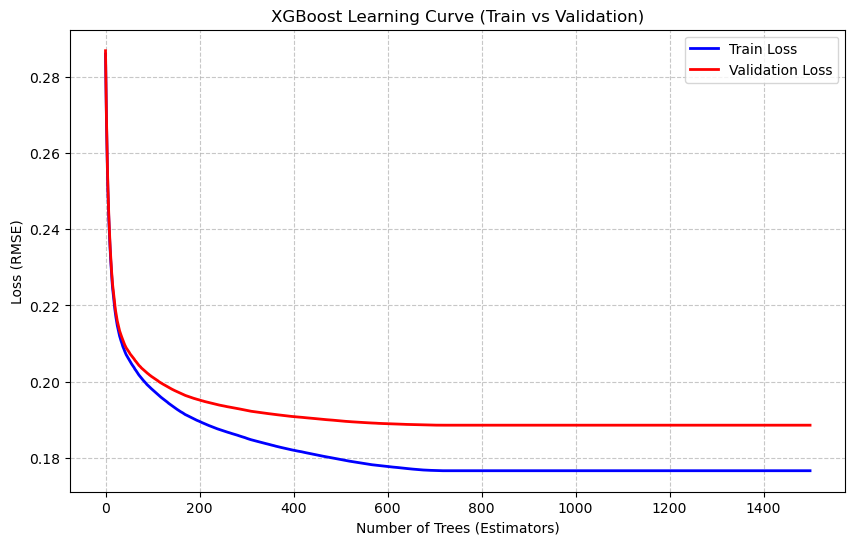

In [75]:
xgb_model_tuned.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)], # 👈 تمرير المجموعتين معاً
    verbose=False # أوقفنا الطباعة المزعجة لأننا سنرسمها بدلاً من ذلك
)

results = xgb_model_tuned.evals_result()

metric_name = list(results['validation_0'].keys())[0]

epochs = len(results['validation_0'][metric_name])
x_axis = range(0, epochs)

plt.figure(figsize=(10, 6))

plt.plot(x_axis, results['validation_0'][metric_name], label='Train Loss', color='blue', linewidth=2)

plt.plot(x_axis, results['validation_1'][metric_name], label='Validation Loss', color='red', linewidth=2)

plt.legend()
plt.xlabel('Number of Trees (Estimators)')
plt.ylabel(f'Loss ({metric_name.upper()})')
plt.title('XGBoost Learning Curve (Train vs Validation)')
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

Submission File

In [ ]:
test_df = pd.read_csv('test.csv')
submission_ids = test_df['id_seqpos']

predictions_df = pd.DataFrame(
    predictions_xgb_tuned, 
    columns=['reactivity', 'deg_Mg_pH10', 'deg_Mg_50C']
)

final_submission = pd.concat([submission_ids, predictions_df], axis=1)

final_submission.to_csv('submission_xgb_tuned.csv', index=False)

✅ تم إنشاء ملف التسليم بنجاح! جاهز للرفع.


# Error Analysis

In [76]:
error_analysis = pd.DataFrame()

#  reactivity
error_analysis['reactivity_actual'] = y_val['reactivity'].values
error_analysis['reactivity_predicted'] = predictions_xgb_tuned[:, 0]
error_analysis['reactivity_error'] = abs(error_analysis['reactivity_actual'] - error_analysis['reactivity_predicted'])

#  deg_Mg_pH10
error_analysis['deg_Mg_pH10_actual'] = y_val['deg_Mg_pH10'].values
error_analysis['deg_Mg_pH10_predicted'] = predictions_xgb_tuned[:, 1]
error_analysis['deg_Mg_pH10_error'] = abs(error_analysis['deg_Mg_pH10_actual'] - error_analysis['deg_Mg_pH10_predicted'])

#  deg_Mg_50C
error_analysis['deg_Mg_50C_actual'] = y_val['deg_Mg_50C'].values
error_analysis['deg_Mg_50C_predicted'] = predictions_xgb_tuned[:, 2]
error_analysis['deg_Mg_50C_error'] = abs(error_analysis['deg_Mg_50C_actual'] - error_analysis['deg_Mg_50C_predicted'])

error_analysis

,reactivity_actual,reactivity_predicted,reactivity_error,deg_Mg_pH10_actual,deg_Mg_pH10_predicted,deg_Mg_pH10_error,deg_Mg_50C_actual,deg_Mg_50C_predicted,deg_Mg_50C_error
0,0.043600,0.050743,0.007143,0.073100,0.106022,0.032922,0.07730,0.077793,0.000493
1,0.124600,0.302781,0.178181,0.195200,0.249375,0.054175,0.16260,0.300215,0.137615
2,0.038600,0.061877,0.023277,0.123600,0.190576,0.066976,0.06390,0.164801,0.100901
3,0.000000,-0.009556,0.009556,0.165600,0.105824,0.059776,0.04430,0.069045,0.024745
4,0.412000,0.392450,0.019550,0.197900,0.240540,0.042640,0.09370,0.280407,0.186707
...,...,...,...,...,...,...,...,...,...
43080,0.977946,0.872751,0.105195,0.893554,0.811495,0.082059,1.01986,0.913879,0.105981
43081,0.198600,0.099362,0.099238,0.306900,0.237333,0.069567,0.30470,0.159791,0.144909
43082,0.289100,0.408302,0.119202,0.478700,0.552173,0.073473,0.41820,0.436674,0.018474
43083,0.000000,0.060905,0.060905,0.000000,0.255370,0.255370,0.13570,0.213335,0.077635


In [77]:
error_analysis = error_analysis.reset_index(drop=True)
X_val_reset = X_val.reset_index(drop=True)
error_analysis_full = pd.concat([error_analysis, X_val_reset], axis=1)

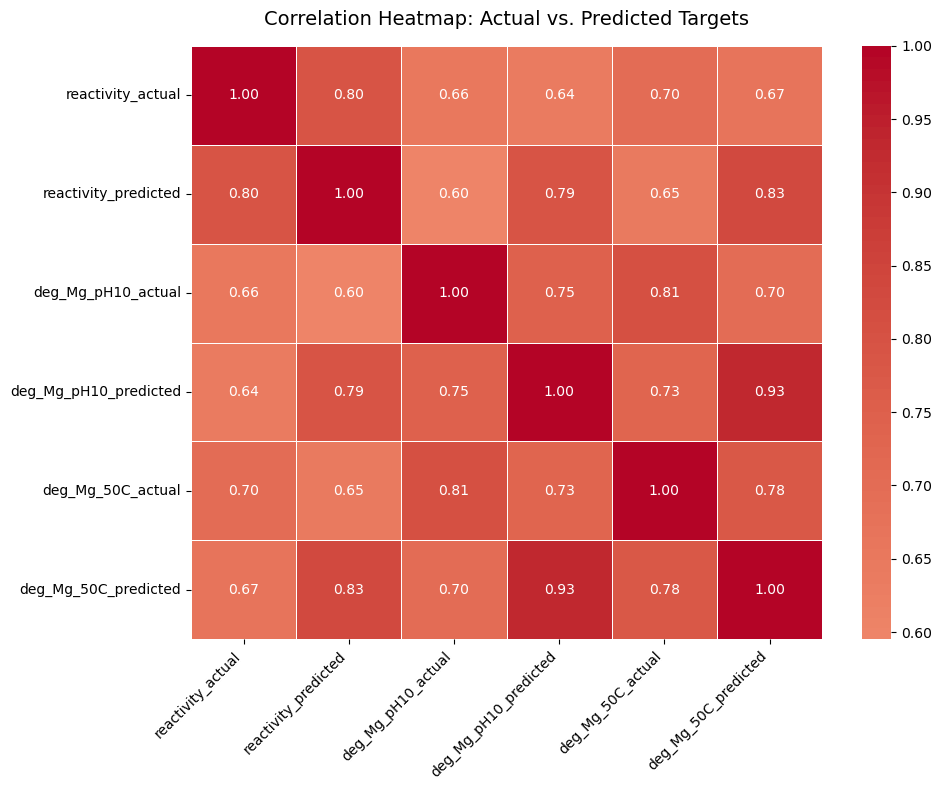

In [78]:
correlation_matrix = error_analysis[[
    'reactivity_actual', 'reactivity_predicted', 
    'deg_Mg_pH10_actual', 'deg_Mg_pH10_predicted', 
    'deg_Mg_50C_actual', 'deg_Mg_50C_predicted'
]].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix, 
    annot=True,          
    cmap='coolwarm',     
    center=0,           
    fmt='.2f',           
    linewidths=0.5
)

plt.title('Correlation Heatmap: Actual vs. Predicted Targets', fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

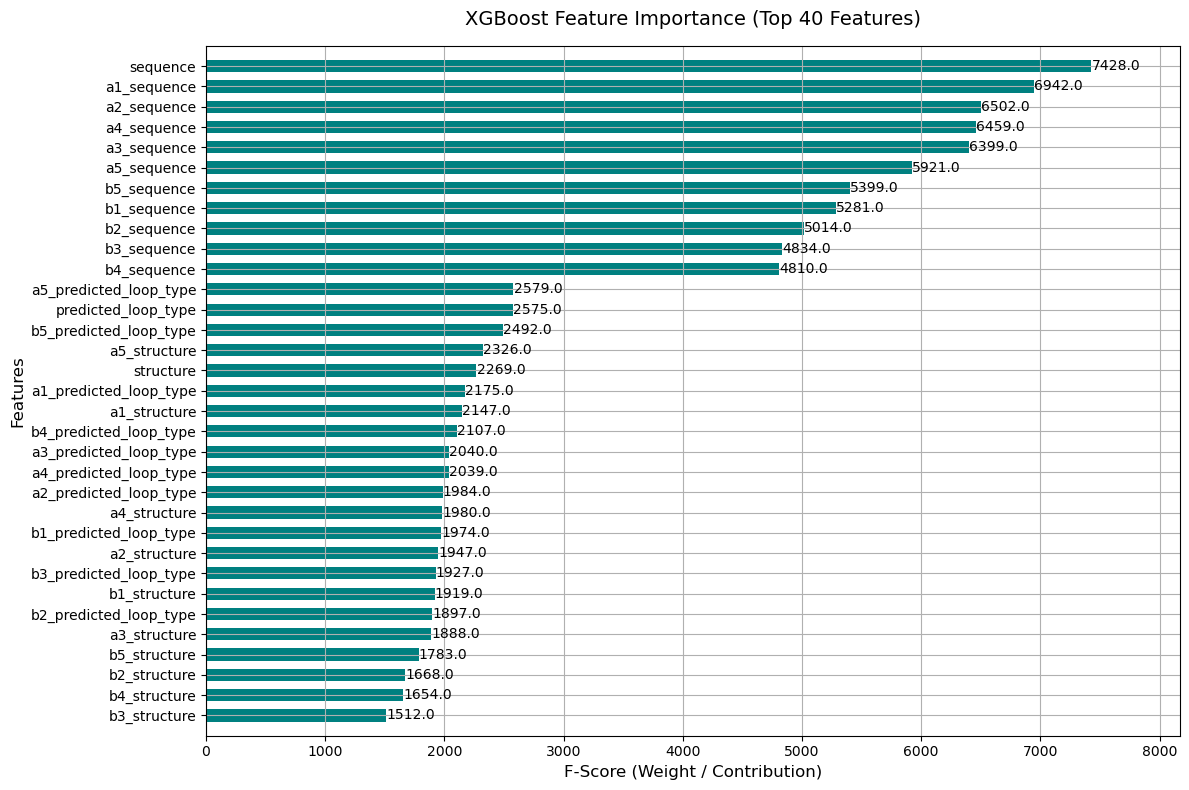

In [79]:

fig, ax = plt.subplots(figsize=(12, 8))

plot_importance(
    xgb_model_tuned, 
    max_num_features=40, 
    ax=ax, 
    height=0.6,          
    color='teal',        
    title=None            
)

# تحسين مظهر النصوص والعناوين
plt.title("XGBoost Feature Importance (Top 40 Features)", fontsize=14, pad=15)
plt.xlabel("F-Score (Weight / Contribution)", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.tight_layout()

plt.show()